In [3]:
#Đọc dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

df = pd.read_csv('../data/NguyenTheHoang_final_eda.csv', low_memory=False)

print(df.shape)
print(df.head())

(158656, 14)
  Transaction ID Transaction Date Product Name  Quantity  Price  \
0    TXN_1961373       2023-09-08       Coffee       2.0    2.0   
1    TXN_4977031       2023-05-16         Cake       4.0    3.0   
2    TXN_4271903       2023-07-19       Cookie       4.0    1.0   
3    TXN_7034554       2023-04-27        Salad       2.0    5.0   
4    TXN_3160411       2023-06-11       Coffee       2.0    2.0   

  Store Location      Source  Sales Amount  Month    Weekday Price Range  \
0       Takeaway  Cafe Sales           4.0      9     Friday         Low   
1       In-store  Cafe Sales          12.0      5    Tuesday      Medium   
2       In-store  Cafe Sales           4.0      7  Wednesday         Low   
3       Takeaway  Cafe Sales          10.0      4   Thursday      Medium   
4       In-store  Cafe Sales           4.0      6     Sunday         Low   

   Source_Cafe Sales  Source_Coffee Shop Sales  Sales Amount (scaled)  
0               True                     False         

In [3]:
#Chọn features đưa vào PCA
features = [
    'Quantity',
    'Price',
    'Sales Amount',
    'Month',
    'Source_Coffee Shop Sales'
]

X = df[features].astype(float)

print(X.head())
print(X.shape)

   Quantity  Price  Sales Amount  Month  Source_Coffee Shop Sales
0       2.0    2.0           4.0    9.0                       0.0
1       4.0    3.0          12.0    5.0                       0.0
2       4.0    1.0           4.0    7.0                       0.0
3       2.0    5.0          10.0    4.0                       0.0
4       2.0    2.0           4.0    6.0                       0.0
(158656, 5)


In [4]:
#Scale bằng StandardScaler
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print(X_scaled[:5])

[[ 0.63823802 -0.52218714 -0.21137186  2.52267169 -3.95355637]
 [ 3.37529855 -0.13720431  1.58394795  0.44583533 -3.95355637]
 [ 3.37529855 -0.90716996 -0.21137186  1.48425351 -3.95355637]
 [ 0.63823802  0.63276133  1.13511799 -0.07337376 -3.95355637]
 [ 0.63823802 -0.52218714 -0.21137186  0.96504442 -3.95355637]]


In [5]:
#Chạy PCA và tính Explained Variance Ratio
pca = PCA()

X_pca = pca.fit_transform(X_scaled)

explained_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

variance_table = pd.DataFrame({
    'Component': np.arange(1, len(explained_variance) + 1),
    'Explained_Variance_Ratio': explained_variance,
    'Cumulative_Variance_Ratio': cumulative_variance
})

print(variance_table)

   Component  Explained_Variance_Ratio  Cumulative_Variance_Ratio
0          1                  0.396998                   0.396998
1          2                  0.293319                   0.690317
2          3                  0.178151                   0.868468
3          4                  0.100817                   0.969285
4          5                  0.030715                   1.000000


In [6]:
#Chọn số component giữ 85-95% variance
n_components = np.argmax(cumulative_variance >= 0.85) + 1

print('So component duoc chon:', n_components)
print('Cumulative variance:', cumulative_variance[n_components - 1])

So component duoc chon: 3
Cumulative variance: 0.868467858784035


Chọn 3 component vì
PC1 + PC2 + PC3 = 86.85%
nằm trong khoảng yêu cầu 85%-95%
PC4 thì lên khoảng 96.93%, vượt mức 95%, nên không chọn

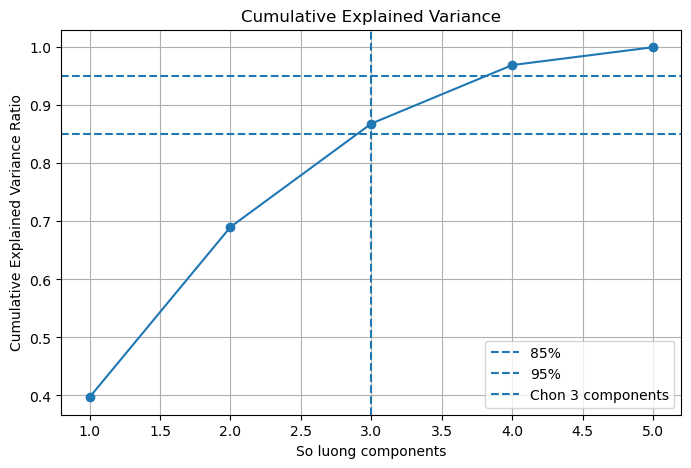

In [7]:
#Vẽ Elbow-style Variance Plot
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(explained_variance) + 1),
    cumulative_variance,
    marker='o'
)

plt.axhline(0.85, linestyle='--', label='85%')
plt.axhline(0.95, linestyle='--', label='95%')
plt.axvline(
    n_components,
    linestyle='--',
    label=f'Chon {n_components} components'
)

plt.xlabel('So luong components')
plt.ylabel('Cumulative Explained Variance Ratio')
plt.title('Cumulative Explained Variance')
plt.legend()
plt.grid(True)

plt.show()

In [8]:
#Tạo ma trận dữ liệu sau PCA
pca_final = PCA(n_components=3)

X_reduced = pca_final.fit_transform(X_scaled)

print('Ma tran sau khi giam chieu:', X_reduced.shape)
print(X_reduced[:10])

Ma tran sau khi giam chieu: (158656, 3)
[[ 2.69719286 -3.0036219   1.63125399]
 [ 4.70135976 -2.11046202 -1.44408948]
 [ 3.75465139 -3.73565482 -0.57258148]
 [ 3.06557576 -0.79955002 -0.42453049]
 [ 2.26268897 -2.50130916  0.30435801]
 [ 6.26654108 -1.15177183 -3.02384716]
 [ 4.31587288 -2.83154071  1.44642972]
 [ 6.04372174 -2.3024911   0.7739485 ]
 [ 6.10068906 -2.56144639 -1.23851804]
 [ 7.57005277 -2.65871006  0.9568408 ]]


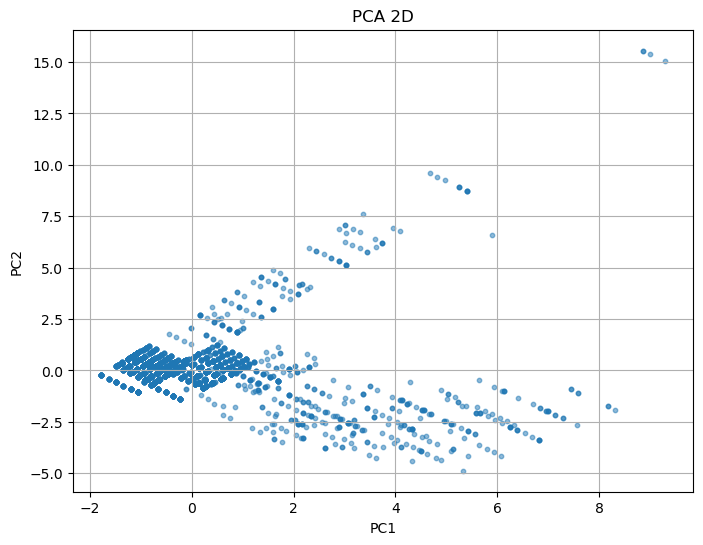

In [9]:
#Scatter Plot 2D
sample_size = min(5000, len(X_reduced))

rng = np.random.default_rng(42)
idx = rng.choice(
    len(X_reduced),
    sample_size,
    replace=False
)

plt.figure(figsize=(8, 6))

plt.scatter(
    X_reduced[idx, 0],
    X_reduced[idx, 1],
    s=10,
    alpha=0.5
)

plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('PCA 2D')
plt.grid(True)

plt.show()

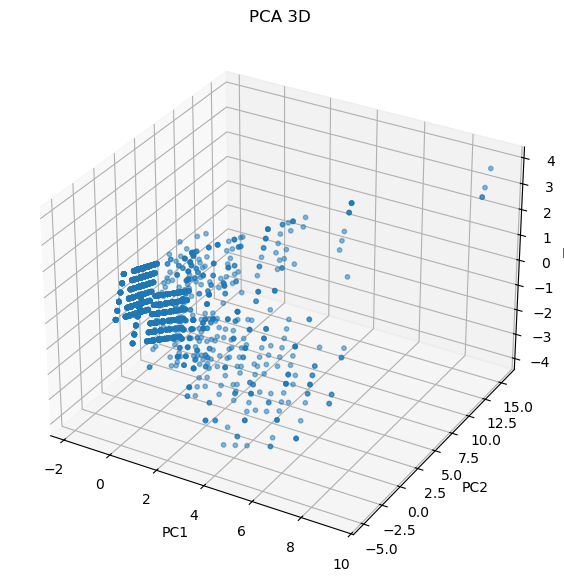

In [10]:
#Scatter Plot 3D
fig = plt.figure(figsize=(9, 7))

ax = fig.add_subplot(111, projection='3d')

ax.scatter(
    X_reduced[idx, 0],
    X_reduced[idx, 1],
    X_reduced[idx, 2],
    s=10,
    alpha=0.5
)

ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.set_zlabel('PC3')
ax.set_title('PCA 3D')

plt.show() 

In [11]:
#Lưu output
pca_output = pd.DataFrame(
    X_reduced,
    columns=['PC1', 'PC2', 'PC3']
)

pca_output.insert(0, 'Transaction ID', df['Transaction ID'].values)

pca_output.to_csv(
    'PhamGiaBao_pca_result.csv',
    index=False
)